# ECG-CaRE — reproduction notebook



This notebook runs the whole ECG-CaRE pipeline from the feature file and writes every
table and figure that can be computed from it:

| Step | What it produces | Paper item |
|---|---|---|
| 1 | Data load, AAMI DS1/DS2 split, class counts | Table I |
| 2 | IQR Winsorization + standardisation (fitted on DS1 only) | Sec. III |
| 3 | Gini feature ranking on DS1 | Fig. 3 |
| 4 | RF variants: RF_ALL, RF_CAUSAL, RF_TOP10, ECG-CaRE-ES | Table V (RF rows) |
| 5 | Five-objective qEHVI MOBO (Sobol + BoTorch) | Table III, Fig. 2 |
| 6 | DART score, top-5 Pareto models, DS2 evaluation | Table VI |
| 7 | Early-stopping sweep on the DART top-1 model | Table VII |
| 8 | Size / latency / RAM / FLOPs comparison | Table VIII (RF rows) |
| 9 | SHAP global + waterfall figures | Fig. 4, Fig. 5, Table IV |
| 10 | Side-by-side: numbers printed in the paper vs numbers from this run | — |

**Not covered here:** the four deep-learning baselines (1D-ResNet, Kiranyaz-CNN,
ECG-Transformer, Causal-DilCNN) need the raw MIT-BIH waveforms. The feature file used
here has no waveforms, so those rows of Tables V and VIII, and the McNemar test against
ECG-Transformer, are outside this notebook.

**How to run:** put `mitbih_23_morph_rr_features.xlsx` in `data/`, then *Run All*.
Set `FAST_MODE = True` in the config cell for a 3–5 minute smoke test.

In [1]:
# ----------------------------------------------------------------------------------
# Imports
# ----------------------------------------------------------------------------------
import os, io, json, time, pickle, warnings, tracemalloc
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, confusion_matrix)

import torch
from botorch.models import SingleTaskGP, ModelListGP
from botorch.models.transforms.outcome import Standardize
from botorch.fit import fit_gpytorch_mll
from botorch.utils.transforms import normalize, unnormalize
from botorch.utils.sampling import draw_sobol_samples
from botorch.acquisition.multi_objective.logei import qLogExpectedHypervolumeImprovement
from botorch.optim import optimize_acqf
from botorch.utils.multi_objective.box_decompositions.non_dominated import (
    FastNondominatedPartitioning)
from botorch.utils.multi_objective.hypervolume import Hypervolume
from botorch.utils.multi_objective.pareto import is_non_dominated
from gpytorch.kernels import MaternKernel, ScaleKernel
from gpytorch.mlls import SumMarginalLogLikelihood

import shap

warnings.filterwarnings("ignore")
print("sklearn", __import__("sklearn").__version__, "| torch", torch.__version__,
      "| botorch", __import__("botorch").__version__, "| shap", shap.__version__)

/usr/local/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


sklearn 1.9.1 | torch 2.15.0+cu132 | botorch 0.18.1 | shap 0.54.1


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 0. Configuration
Everything a user may want to change is in this one cell.

In [2]:
# ----------------------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------------------
DATA_XLSX = "data/mitbih_23_morph_rr_features.xlsx"   # input feature file
CACHE_PKL = "data/cache.pkl"                          # fast-reload cache (auto-created)
OUT_DIR   = "results"                                 # CSV / JSON tables
FIG_DIR   = "figures"                                 # PNG figures
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

# ----------------------------------------------------------------------------------
# Run size.  FAST_MODE = True -> tiny MOBO budget, only to check that the code runs.
# The paper protocol is 20 Sobol + 30 qEHVI = 50 evaluations.
# ----------------------------------------------------------------------------------
FAST_MODE = False
N_INIT, N_BO = (6, 4) if FAST_MODE else (20, 30)
CV_FOLDS = 3              # GroupKFold on DS1, groups = record id (no patient leakage)
SEED     = 42

# ----------------------------------------------------------------------------------
# AAMI EC57 inter-patient split (de Chazal).  Paced records 102/104/107/217 are excluded.
# ----------------------------------------------------------------------------------
DS1 = [101,106,108,109,112,114,115,116,118,119,122,124,201,203,205,207,208,209,215,220,223,230]
DS2 = [100,103,105,111,113,117,121,123,200,202,210,212,213,214,219,221,222,228,231,232,233,234]

# 24 causal features (Table II).  RR_next is NOT in this list: it needs the next beat.
CAUSAL = ['A_P','t_P','width_P','area_P',
          'A_Q','A_R','A_S','A_QRS','QRS_duration','width_QRS','area_QRS',
          'slope_QR','slope_RS','max_slope_QRS','mean_slope_QRS',
          'A_T','t_T','width_T','area_T',
          'PR_interval','QT_interval','ST_interval','PT_interval','RR_prev']
NONCAUSAL = CAUSAL + ['RR_next']            # used only by the RF_ALL reference model
CLASSES   = ['N', 'S', 'V', 'F', 'Q']
N_CLS     = 5

# ----------------------------------------------------------------------------------
# Baseline Random Forest used by RF_ALL / RF_CAUSAL / RF_TOP10 / ECG-CaRE-ES.
# (The paper does not list these values; change them here if your run used others.)
# ----------------------------------------------------------------------------------
BASE_RF = dict(n_estimators=100, max_depth=15, min_samples_leaf=3, min_samples_split=5,
               max_features=0.7, class_weight='balanced')

# ----------------------------------------------------------------------------------
# Early stopping (Eq. 1-2).
#   ES_TAUS : thresholds swept in Table VII (1.00 = early stopping off).
#   K_MIN   : minimum trees before a stop is allowed.  Without it Eq. 2 stops at tree 1
#             whenever the first tree lands in a pure leaf (probability = 1.0).
# ----------------------------------------------------------------------------------
ES_TAUS    = [1.00, 0.90, 0.85, 0.70]
ES_DEFAULT = 0.85
K_MIN      = 5

# ----------------------------------------------------------------------------------
# MOBO search space (Table III).  15 dimensions.
#   tau_* are DECISION thresholds: predicted class = argmax_c  p_c / tau_c.
#   A lower tau_c makes class c easier to predict (direct FNR control).
#   They are different from the early-stopping threshold tau in Eq. 2.
# ----------------------------------------------------------------------------------
SPACE = {                       # name: (low, high, type)
    'n_estimators'     : (10, 150, 'int'),
    'max_depth'        : (5, 25, 'int'),
    'min_samples_leaf' : (1, 20, 'int'),
    'min_samples_split': (2, 20, 'int'),
    'max_features'     : (0.3, 1.0, 'float'),
    'n_features'       : (5, 24, 'int'),       # top-k features by DS1 Gini rank
    'w_S': (1, 20, 'float'), 'w_V': (1, 20, 'float'),
    'w_F': (1, 20, 'float'), 'w_Q': (1, 20, 'float'),
    'tau_N': (0.20, 0.60, 'float'),
    'tau_S': (0.05, 0.40, 'float'), 'tau_V': (0.05, 0.40, 'float'),
    'tau_F': (0.05, 0.40, 'float'), 'tau_Q': (0.05, 0.40, 'float'),
}
OBJ_NAMES = ['-BalAcc', 'FNR_abn', 'Latency_ms', 'RAM_KB', 'Flash_KB']   # all minimised

# ----------------------------------------------------------------------------------
# DART score (Eq. 5)
# ----------------------------------------------------------------------------------
W_D, W_E, W_ED  = 0.50, 0.30, 0.20
LAT_LIMIT_MS    = 10.0      # Ed criterion 1: single-beat CPU latency budget
FLASH_LIMIT_KB  = 1024.0    # Ed criterion 2: 1 MB flash (STM32F446-class part)
DIVERSITY_DIST  = 0.05      # min distance between top-5 picks in normalised objective space

# SHAP
SHAP_PER_CLASS = 120        # beats per class from DS2 (Q has only 7) -> 487 beats

np.random.seed(SEED); torch.manual_seed(SEED)
DT = torch.double

## 1. Data and DS1 / DS2 split  (Table I)

In [3]:
def load_data():
    """Read the feature file once, then reuse a pickle cache (xlsx parsing is slow)."""
    if os.path.exists(CACHE_PKL):
        return pd.read_pickle(CACHE_PKL)
    df = pd.read_excel(DATA_XLSX)
    df.to_pickle(CACHE_PKL)
    return df

df  = load_data()
df1 = df[df.record.isin(DS1)].dropna(subset=NONCAUSAL + ['label']).reset_index(drop=True)
df2 = df[df.record.isin(DS2)].dropna(subset=NONCAUSAL + ['label']).reset_index(drop=True)
y1, y2 = df1.label.values.astype(int), df2.label.values.astype(int)
g1     = df1.record.values                      # CV groups = record id

tab1 = pd.DataFrame({'Class': CLASSES,
                     'DS1 beats': np.bincount(y1, minlength=N_CLS),
                     'DS2 beats': np.bincount(y2, minlength=N_CLS)})
tab1.to_csv(f"{OUT_DIR}/table1_class_counts.csv", index=False)
print(f"DS1: {len(df1):,} beats, {df1.record.nunique()} records | "
      f"DS2: {len(df2):,} beats, {df2.record.nunique()} records")
tab1

DS1: 50,977 beats, 22 records | DS2: 49,668 beats, 22 records


,Class,DS1 beats,DS2 beats
0,N,45824,44218
1,S,943,1836
2,V,3788,3219
3,F,414,388
4,Q,8,7


## 2. Preprocessing
IQR Winsorization (clip to Q1 − 1.5·IQR … Q3 + 1.5·IQR) and z-score scaling.
Both are fitted on **DS1 only** and then applied to DS2.

In [4]:
def fit_preproc(X_train):
    """Return a function that winsorizes and standardises with DS1 statistics."""
    q1, q3 = np.percentile(X_train, 25, axis=0), np.percentile(X_train, 75, axis=0)
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    sc = StandardScaler().fit(np.clip(X_train, lo, hi))
    return lambda X: sc.transform(np.clip(X, lo, hi)).astype(np.float32)

prep_c = fit_preproc(df1[CAUSAL].values)        # 24 causal features
prep_a = fit_preproc(df1[NONCAUSAL].values)     # 25 features (with RR_next)
X1,  X2  = prep_c(df1[CAUSAL].values),    prep_c(df2[CAUSAL].values)
X1a, X2a = prep_a(df1[NONCAUSAL].values), prep_a(df2[NONCAUSAL].values)
print("DS1", X1.shape, "| DS2", X2.shape)

DS1 (50977, 24) | DS2 (49668, 24)


## 3. Shared helpers
Metrics, the decision rule, vectorised early stopping, and the hardware proxies.

In [5]:
def recalls(y, p):
    """Per-class recall; NaN for a class that has no beats in y."""
    r = np.full(N_CLS, np.nan)
    for c in range(N_CLS):
        m = (y == c)
        if m.any(): r[c] = np.mean(p[m] == c)
    return r

def all_metrics(y, p):
    """Every diagnostic number reported in the paper, for one prediction vector."""
    r = recalls(y, p)
    return dict(Acc=accuracy_score(y, p) * 100,
                BalAcc=np.nanmean(r) * 100,                 # mean recall over present classes
                MCC=matthews_corrcoef(y, p),
                MaF1=f1_score(y, p, average='macro', labels=range(N_CLS), zero_division=0),
                FNR_N=(1 - r[0]) * 100, FNR_S=(1 - r[1]) * 100, FNR_V=(1 - r[2]) * 100,
                FNR_F=(1 - r[3]) * 100, FNR_Q=(1 - r[4]) * 100,
                FNR_abn=np.nanmean(1 - r[1:]) * 100)        # mean FNR over S, V, F, Q

def decide(P, tau=None):
    """Decision rule.  tau=None -> plain argmax.  Otherwise argmax_c P[:,c] / tau[c]."""
    return P.argmax(1) if tau is None else (P / np.asarray(tau)[None, :]).argmax(1)

def tree_probas(rf, X, order=None):
    """Per-tree class probabilities, shape (T, n, 5).  Uses the low-level tree API (fast)."""
    X32   = np.ascontiguousarray(X, dtype=np.float32)
    order = range(len(rf.estimators_)) if order is None else order
    out   = np.zeros((len(rf.estimators_), X.shape[0], N_CLS), dtype=np.float32)
    for k, i in enumerate(order):
        v = rf.estimators_[i].tree_.predict(X32).reshape(X32.shape[0], -1)   # (n, classes)
        out[k][:, rf.classes_.astype(int)] = v / v.sum(1, keepdims=True)   # map to 5 columns
    return out

def forest_proba(rf, X):
    """Full-forest probability with a fixed 5-column layout (a CV fold may miss class Q)."""
    P = np.zeros((X.shape[0], N_CLS), dtype=np.float32)
    P[:, rf.classes_.astype(int)] = rf.predict_proba(X)
    return P

def early_stop(TP, tau_es, tau_dec=None, k_min=K_MIN):
    """Eq. 1-2, vectorised over beats.
    TP      : (T, n, 5) per-tree probabilities, already in evaluation order
    tau_es  : confidence threshold; >= 1.0 switches early stopping off
    returns : predictions, fraction of trees used per beat
    """
    T, n, _ = TP.shape
    cum = np.cumsum(TP, axis=0) / np.arange(1, T + 1, dtype=np.float32)[:, None, None]  # Eq. 1
    if tau_es >= 1.0:
        k = np.full(n, T - 1)
    else:
        ok = cum.max(2) >= tau_es                 # Eq. 2 condition, per tree count
        ok[:max(k_min - 1, 0)] = False            # not before k_min trees
        k = np.where(ok.any(0), ok.argmax(0), T - 1)
    P = cum[k, np.arange(n)]
    return decide(P, tau_dec), (k + 1) / T

def order_trees(rf, X, y, groups, frac=0.15):
    """Sort trees by their individual balanced accuracy on a DS1 record subset (Sec. III-B).
    The subset is part of the training data, so this is only an ordering heuristic."""
    _, va = next(GroupShuffleSplit(1, test_size=frac, random_state=SEED).split(X, y, groups))
    TP = tree_probas(rf, X[va])
    score = [np.nanmean(recalls(y[va], TP[t].argmax(1))) for t in range(TP.shape[0])]
    return list(np.argsort(score)[::-1])

# ---------------------------- hardware proxies (desktop CPU) ----------------------------
def latency_ms(rf, X, order=None, tau_es=1.0, k_min=K_MIN, n_beats=200):
    """Mean / std single-beat latency of a sequential tree-by-tree inference loop.
    Same loop for every model and every tau, so the numbers are comparable to each other.
    These are desktop-CPU, Python-level timings, not MCU timings."""
    order = range(len(rf.estimators_)) if order is None else order
    trees = [rf.estimators_[i].tree_ for i in order]
    idx   = np.random.RandomState(SEED).choice(len(X), min(n_beats, len(X)), replace=False)
    X32   = np.ascontiguousarray(X[idx], dtype=np.float32)
    ts = []
    for i in range(len(X32)):
        x = X32[i:i + 1]; cp = 0.0
        t0 = time.perf_counter()
        for k, tr in enumerate(trees, 1):
            v = tr.predict(x).ravel(); cp = cp + v / v.sum()
            if tau_es < 1.0 and k >= k_min and cp.max() / k >= tau_es: break
        ts.append((time.perf_counter() - t0) * 1e3)
    return float(np.mean(ts)), float(np.std(ts))

def ram_kb(rf, X):
    """Peak Python-heap allocation of one predict_proba call (tracemalloc), in KB."""
    nj, rf.n_jobs = rf.n_jobs, 1
    x = X[:1]; rf.predict_proba(x)                 # warm-up
    tracemalloc.start(); rf.predict_proba(x)
    peak = tracemalloc.get_traced_memory()[1]; tracemalloc.stop()
    rf.n_jobs = nj
    return peak / 1024

def flash_kb(rf):
    """Serialised model size (pickle), in KB.  Upper bound for a compiled C export."""
    return len(pickle.dumps(rf)) / 1024

def n_nodes(rf):
    return int(sum(t.tree_.node_count for t in rf.estimators_))

def flops(rf, X, frac_trees=1.0, n=2000):
    """Analytical cost: mean number of threshold comparisons per beat."""
    idx  = np.random.RandomState(SEED).choice(len(X), min(n, len(X)), replace=False)
    path = rf.decision_path(X[idx])[0]             # visited nodes, all trees
    comps = path.sum() / len(idx) - len(rf.estimators_)     # minus one leaf per tree
    return float(comps * frac_trees)

def make_rf(**kw):
    return RandomForestClassifier(random_state=SEED, n_jobs=-1, **kw)

## 4. Gini feature ranking on DS1  (Fig. 3)
Computed on DS1 only. The ranking is used by `RF_TOP10` and by the `n_features`
dimension of the MOBO search (top-k features, **not** the first k columns).

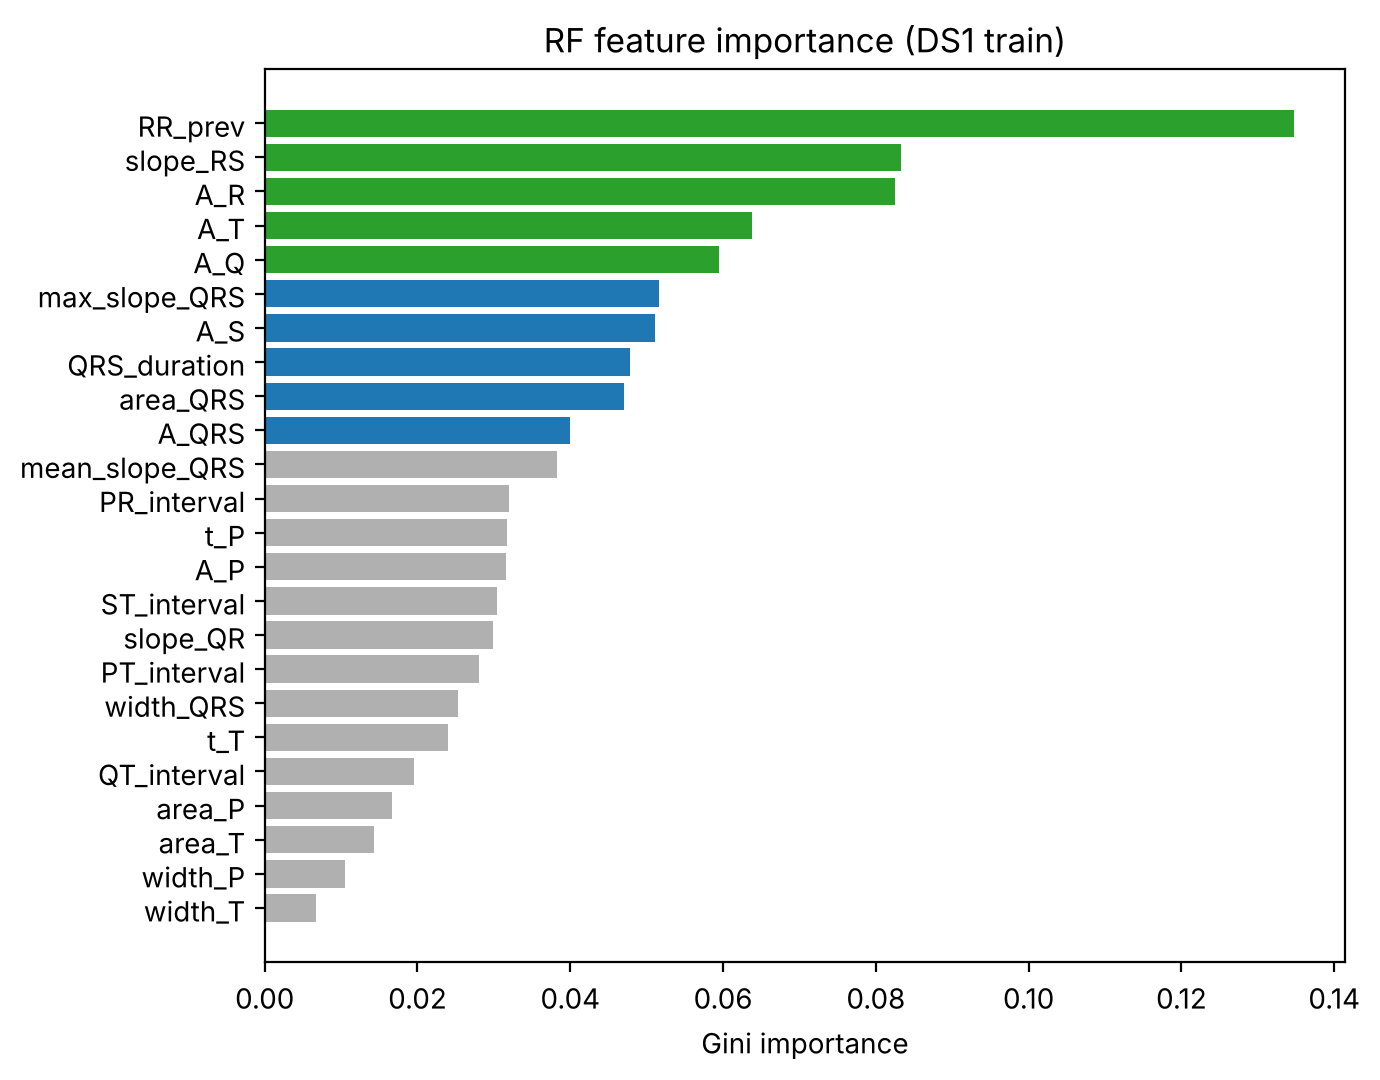

Top-10: ['RR_prev', 'slope_RS', 'A_R', 'A_T', 'A_Q', 'max_slope_QRS', 'A_S', 'QRS_duration', 'area_QRS', 'A_QRS']


In [6]:
rf_rank = make_rf(n_estimators=200, max_depth=15, class_weight='balanced').fit(X1, y1)
gini    = rf_rank.feature_importances_
RANK    = list(np.argsort(gini)[::-1])            # column indices, most important first
TOP10   = RANK[:10]

fig, ax = plt.subplots(figsize=(7, 5.5))
cols = ['#2ca02c' if i < 5 else '#1f77b4' if i < 10 else '#b0b0b0' for i in range(len(RANK))]
ax.barh([CAUSAL[i] for i in RANK][::-1], gini[RANK][::-1], color=cols[::-1])
ax.set_xlabel("Gini importance"); ax.set_title("RF feature importance (DS1 train)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig3_feature_importance.png", dpi=200); plt.show()
pd.DataFrame({'rank': range(1, 25), 'feature': [CAUSAL[i] for i in RANK],
              'gini': gini[RANK]}).to_csv(f"{OUT_DIR}/gini_ranking.csv", index=False)
print("Top-10:", [CAUSAL[i] for i in TOP10])

## 5. Random Forest variants  (Table V, RF rows)
* `RF_ALL` — 25 features including `RR_next` (non-causal reference)
* `RF_CAUSAL` — 24 causal features
* `RF_TOP10` — top-10 causal features by Gini rank
* `ECG-CaRE-ES` — `RF_CAUSAL` with early stopping at τ = 0.85

All are trained on DS1 and tested once on DS2.

In [7]:
rows5, MODELS = {}, {}        # MODELS keeps (rf, X_test, tree order, decision taus, ES tau)

rf_all = make_rf(**BASE_RF).fit(X1a, y1)
rows5['RF_ALL (non-causal)'] = all_metrics(y2, rf_all.predict(X2a).astype(int))

rf_causal = make_rf(**BASE_RF).fit(X1, y1)
pred_causal = rf_causal.predict(X2).astype(int)
rows5['RF_CAUSAL'] = all_metrics(y2, pred_causal)
MODELS['RF_CAUSAL'] = (rf_causal, X2, None, None, 1.0)

rf_top10 = make_rf(**BASE_RF).fit(X1[:, TOP10], y1)
rows5['RF_TOP10'] = all_metrics(y2, rf_top10.predict(X2[:, TOP10]).astype(int))
MODELS['RF_TOP10'] = (rf_top10, X2[:, TOP10], None, None, 1.0)

order_causal = order_trees(rf_causal, X1, y1, g1)
TP_causal    = tree_probas(rf_causal, X2, order_causal)
pred_es, frac_es = early_stop(TP_causal, ES_DEFAULT)
rows5['ECG-CaRE-ES'] = all_metrics(y2, pred_es)
MODELS['ECG-CaRE-ES'] = (rf_causal, X2, order_causal, None, ES_DEFAULT)
print(f"ECG-CaRE-ES: mean trees used = {frac_es.mean() * 100:.1f}%")
del TP_causal

pd.DataFrame(rows5).T.round(3)

ECG-CaRE-ES: mean trees used = 34.0%


,Acc,BalAcc,MCC,MaF1,FNR_N,FNR_S,FNR_V,FNR_F,FNR_Q,FNR_abn
RF_ALL (non-causal),84.954,41.881,0.447,0.366,11.565,90.468,12.271,76.289,100.0,69.757
RF_CAUSAL,84.195,37.579,0.419,0.339,12.029,95.370,12.954,91.753,100.0,75.019
RF_TOP10,81.068,36.326,0.375,0.334,15.489,93.900,14.135,94.845,100.0,75.720
ECG-CaRE-ES,84.106,37.391,0.415,0.338,12.061,95.316,13.917,91.753,100.0,75.246


## 6. Five-objective MOBO with qEHVI  (Sec. III-C, Table III, Fig. 2)

Objectives, all minimised: `(−BalAcc, FNR_abn, Latency, RAM, Flash)`.

* BalAcc and FNR_abn come from pooled out-of-fold predictions of a 3-fold GroupKFold on
  DS1 (groups = record). DS2 is never touched during the search.
* Class weights **and** decision thresholds are applied inside the CV, so every one of the
  15 search dimensions changes the objectives the surrogate sees.
* Latency, RAM and Flash are measured on a forest refitted on all of DS1.
* Surrogate: one GP per objective, ARD Matérn-5/2 kernel. Acquisition: qLogEHVI, q = 1.
* Reference point: set after the Sobol phase from the worst observed value per objective.

In [8]:
NAMES  = list(SPACE)
DIM    = len(NAMES)
BOUNDS = torch.tensor([[SPACE[k][0] for k in NAMES], [SPACE[k][1] for k in NAMES]], dtype=DT)

def to_params(x):
    """Search-space vector -> dict (integers rounded, values clipped to the bounds)."""
    p = {}
    for v, k in zip(np.asarray(x, dtype=float), NAMES):
        lo, hi, typ = SPACE[k]
        v = float(np.clip(v, lo, hi))
        p[k] = int(round(v)) if typ == 'int' else v
    return p

def rf_from(p):
    return make_rf(n_estimators=p['n_estimators'], max_depth=p['max_depth'],
                   min_samples_leaf=p['min_samples_leaf'],
                   min_samples_split=p['min_samples_split'], max_features=p['max_features'],
                   class_weight={0: 1.0, 1: p['w_S'], 2: p['w_V'], 3: p['w_F'], 4: p['w_Q']})

def taus_of(p):
    return np.array([p['tau_N'], p['tau_S'], p['tau_V'], p['tau_F'], p['tau_Q']])

def evaluate(p):
    """One MOBO trial.  Returns the 5 objectives (minimisation) and a dict of all metrics."""
    cols, tau = RANK[:p['n_features']], taus_of(p)
    Xf  = X1[:, cols]
    oof = np.zeros(len(y1), dtype=int)                       # pooled out-of-fold predictions
    for tr, va in GroupKFold(CV_FOLDS).split(Xf, y1, g1):
        rf = rf_from(p).fit(Xf[tr], y1[tr])
        oof[va] = decide(forest_proba(rf, Xf[va]), tau)
    m  = all_metrics(y1, oof)
    rf = rf_from(p).fit(Xf, y1)                              # hardware proxies: full DS1 fit
    lat, _ = latency_ms(rf, Xf, n_beats=60)
    info = dict(cv_Acc=m['Acc'], cv_BalAcc=m['BalAcc'], cv_MCC=m['MCC'], cv_FNR_S=m['FNR_S'],
                cv_FNR_V=m['FNR_V'], cv_FNR_abn=m['FNR_abn'], Latency_ms=lat,
                RAM_KB=ram_kb(rf, Xf), Flash_KB=flash_kb(rf), nodes=n_nodes(rf))
    f = np.array([-m['BalAcc'] / 100, m['FNR_abn'] / 100, lat, info['RAM_KB'], info['Flash_KB']])
    return f, info

def fit_gp(X, Y_max):
    """Independent GPs (one per objective) with an ARD Matern-5/2 kernel."""
    Xn = normalize(X, BOUNDS)
    gp = ModelListGP(*[SingleTaskGP(Xn, Y_max[:, j:j + 1],
                                    covar_module=ScaleKernel(MaternKernel(nu=2.5, ard_num_dims=DIM)),
                                    outcome_transform=Standardize(m=1))
                       for j in range(Y_max.shape[-1])])
    fit_gpytorch_mll(SumMarginalLogLikelihood(gp.likelihood, gp))
    return gp

def hypervolume(Y_max, ref):
    """Dominated hypervolume of the points that are strictly better than the reference."""
    Y = Y_max[(Y_max > ref).all(dim=1)]
    return 0.0 if len(Y) == 0 else float(Hypervolume(ref).compute(Y[is_non_dominated(Y)]))

In [9]:
# ----------------------------------------------------------------------------------
# Run the optimisation.  Roughly 1 hour on a 2-core CPU with the full 20 + 30 budget.
# ----------------------------------------------------------------------------------
t0 = time.time(); TX, TY, INFO = [], [], []

def run_trial(x, phase):
    p = to_params(x)
    f, info = evaluate(p)
    TX.append(np.array([p[k] for k in NAMES], dtype=float)); TY.append(f)
    INFO.append(dict(trial=len(TY), phase=phase, **p, **info))
    print(f"[{phase:5s} {len(TY):2d}] BalAcc={info['cv_BalAcc']:5.1f}%  FNRabn={info['cv_FNR_abn']:5.1f}%  "
          f"Lat={f[2]:6.3f}ms  RAM={f[3]:6.1f}KB  Flash={f[4]:7.0f}KB  ({(time.time() - t0) / 60:4.1f} min)")

# Phase 1: Sobol quasi-random initialisation
sobol = draw_sobol_samples(bounds=BOUNDS, n=N_INIT, q=1, seed=SEED).squeeze(1)
for x in sobol: run_trial(x.numpy(), 'sobol')

# Reference point (maximisation convention): a little worse than the worst Sobol point.
Y0  = -torch.tensor(np.array(TY), dtype=DT)
REF = Y0.min(0).values - 0.1 * (Y0.max(0).values - Y0.min(0).values).clamp_min(1e-6)
HV  = [hypervolume(-torch.tensor(np.array(TY[:i]), dtype=DT), REF) for i in range(1, N_INIT + 1)]

# Phase 2: qEHVI Bayesian optimisation
unit = torch.stack([torch.zeros(DIM, dtype=DT), torch.ones(DIM, dtype=DT)])
for it in range(N_BO):
    Xt, Yt = torch.tensor(np.array(TX), dtype=DT), -torch.tensor(np.array(TY), dtype=DT)
    try:
        gp  = fit_gp(Xt, Yt)
        acq = qLogExpectedHypervolumeImprovement(
            model=gp, ref_point=REF,
            partitioning=FastNondominatedPartitioning(ref_point=REF, Y=Yt))
        cand, _ = optimize_acqf(acq, bounds=unit, q=1, num_restarts=4, raw_samples=96,
                                options={"batch_limit": 4, "maxiter": 80})
        x_next = unnormalize(cand.detach().squeeze(0), BOUNDS).numpy()
    except Exception as e:                                   # numerical failure -> random point
        print("   surrogate/acquisition failed, random candidate:", str(e)[:80])
        x_next = unnormalize(torch.rand(DIM, dtype=DT), BOUNDS).numpy()
    run_trial(x_next, 'qehvi')
    HV.append(hypervolume(-torch.tensor(np.array(TY), dtype=DT), REF))

TX, TY = np.array(TX), np.array(TY)
trials = pd.DataFrame(INFO)
trials['pareto'] = is_non_dominated(-torch.tensor(TY, dtype=DT)).numpy()
trials['HV'] = HV
trials.to_csv(f"{OUT_DIR}/mobo_all_trials.csv", index=False)
print(f"\nDone in {(time.time() - t0) / 60:.1f} min | Pareto size = {trials.pareto.sum()} / {len(trials)}")

[sobol  1] BalAcc= 32.6%  FNRabn= 74.2%  Lat= 0.719ms  RAM=  14.6KB  Flash=   2862KB  ( 0.2 min)


[sobol  2] BalAcc= 33.2%  FNRabn= 80.8%  Lat= 0.170ms  RAM=  13.5KB  Flash=   3160KB  ( 0.4 min)


[sobol  3] BalAcc= 33.0%  FNRabn= 79.8%  Lat= 0.176ms  RAM=  13.6KB  Flash=   2217KB  ( 0.6 min)


[sobol  4] BalAcc= 33.3%  FNRabn= 76.8%  Lat= 0.417ms  RAM=  13.9KB  Flash=   6782KB  ( 1.0 min)


[sobol  5] BalAcc= 39.0%  FNRabn= 72.6%  Lat= 0.534ms  RAM=  14.0KB  Flash=   5905KB  ( 1.4 min)


[sobol  6] BalAcc= 34.0%  FNRabn= 77.3%  Lat= 0.251ms  RAM=  13.7KB  Flash=   3138KB  ( 1.7 min)


... (40 outputs left out)

[qehvi 47] BalAcc= 29.6%  FNRabn= 69.7%  Lat= 0.045ms  RAM=  13.3KB  Flash=    868KB  (10.6 min)


[qehvi 48] BalAcc= 26.9%  FNRabn= 85.3%  Lat= 0.040ms  RAM=  13.3KB  Flash=    463KB  (10.8 min)


[qehvi 49] BalAcc= 33.0%  FNRabn= 80.3%  Lat= 0.045ms  RAM=  13.4KB  Flash=   1531KB  (11.0 min)


[qehvi 50] BalAcc= 32.0%  FNRabn= 75.5%  Lat= 0.043ms  RAM=  13.4KB  Flash=    823KB  (11.3 min)

Done in 11.3 min | Pareto size = 14 / 50


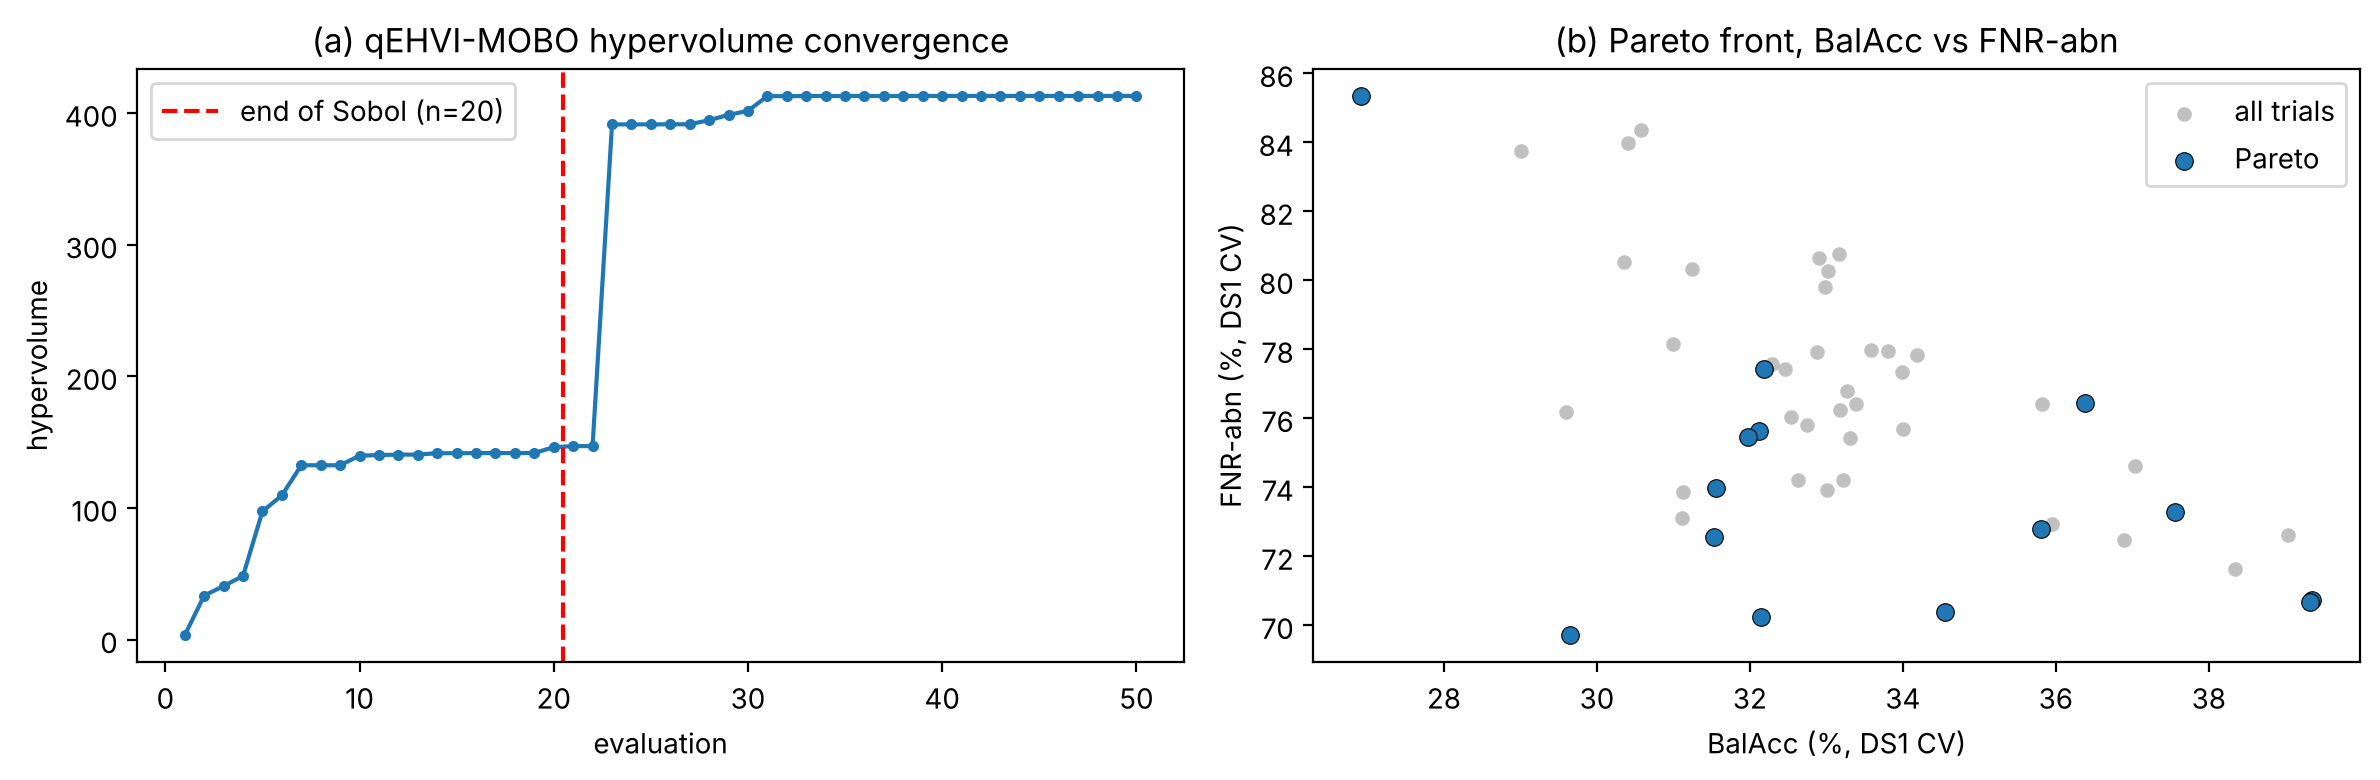

HV gain in Sobol phase : 142.9
HV gain in qEHVI phase : 266.9


In [10]:
# Fig. 2: hypervolume convergence and Pareto front (CV objectives)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, len(HV) + 1), HV, 'o-', ms=3)
ax[0].axvline(N_INIT + 0.5, color='r', ls='--', label=f'end of Sobol (n={N_INIT})')
ax[0].set_xlabel("evaluation"); ax[0].set_ylabel("hypervolume"); ax[0].legend()
ax[0].set_title("(a) qEHVI-MOBO hypervolume convergence")
par = trials[trials.pareto]
ax[1].scatter(trials.cv_BalAcc, trials.cv_FNR_abn, c='#c0c0c0', s=18, label='all trials')
ax[1].scatter(par.cv_BalAcc, par.cv_FNR_abn, c='#1f77b4', s=40, edgecolor='k', lw=.4, label='Pareto')
ax[1].set_xlabel("BalAcc (%, DS1 CV)"); ax[1].set_ylabel("FNR-abn (%, DS1 CV)"); ax[1].legend()
ax[1].set_title("(b) Pareto front, BalAcc vs FNR-abn")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig2_mobo.png", dpi=200); plt.show()
print(f"HV gain in Sobol phase : {HV[N_INIT - 1] - HV[0]:.4g}")
print(f"HV gain in qEHVI phase : {HV[-1] - HV[N_INIT - 1]:.4g}")

## 7. DART score and top-5 selection  (Eq. 5, Table VI)

`DART = 0.50·D + 0.30·E + 0.20·Ed`, computed on the Pareto set with the DS1-CV objectives
(model selection must not look at DS2):

* `D  = 0.5·BalAcc + 0.5·(1 − FNR_abn)`, both terms min-max-normalised within the Pareto set
* `E  = mean of min-max-normalised (inverted) latency, RAM and flash within the Pareto set`
* `Ed = fraction of deployability criteria met`: latency ≤ `LAT_LIMIT_MS`, flash ≤ `FLASH_LIMIT_KB`

The five picks are chosen greedily by DART with a minimum distance in normalised
objective space. Each pick is then refitted on DS1 and tested once on DS2.

In [11]:
def minmax_inv(v):
    """Min-max normalise and invert, so that 1 = best (smallest) and 0 = worst."""
    v = np.asarray(v, dtype=float)
    return np.ones_like(v) if np.ptp(v) == 0 else (v.max() - v) / np.ptp(v)

P = trials[trials.pareto].copy().reset_index(drop=True)
P['D']    = 0.5 * (1 - minmax_inv(P.cv_BalAcc)) + 0.5 * minmax_inv(P.cv_FNR_abn)
P['E']    = (minmax_inv(P.Latency_ms) + minmax_inv(P.RAM_KB) + minmax_inv(P.Flash_KB)) / 3
P['Ed']   = ((P.Latency_ms <= LAT_LIMIT_MS).astype(float) + (P.Flash_KB <= FLASH_LIMIT_KB).astype(float)) / 2
P['DART'] = W_D * P.D + W_E * P.E + W_ED * P.Ed

# greedy, diversity-aware top-5
Z = np.column_stack([minmax_inv(P[c]) for c in ['cv_BalAcc', 'cv_FNR_abn', 'Latency_ms', 'RAM_KB', 'Flash_KB']])  # diversity space
top = []
for i in np.argsort(-P.DART.values):
    if all(np.linalg.norm(Z[i] - Z[j]) >= DIVERSITY_DIST for j in top): top.append(int(i))
    if len(top) == 5: break
P['rank'] = np.nan
for r, i in enumerate(top, 1): P.loc[i, 'rank'] = r
P.to_csv(f"{OUT_DIR}/pareto_dart.csv", index=False)
P.loc[top, ['rank', 'DART', 'D', 'E', 'Ed', 'cv_BalAcc', 'cv_FNR_abn', 'Latency_ms', 'RAM_KB', 'Flash_KB']].round(3)

,rank,DART,D,E,Ed,cv_BalAcc,cv_FNR_abn,Latency_ms,RAM_KB,Flash_KB
7,1.0,0.901,0.813,0.983,1.0,37.557,73.299,0.043,13.322,464.148
3,2.0,0.872,0.967,0.961,0.5,39.355,70.745,0.048,13.322,1442.101
9,3.0,0.828,0.665,0.984,1.0,36.384,76.447,0.041,13.322,464.352
11,4.0,0.797,0.610,0.974,1.0,29.648,69.712,0.045,13.322,868.237
4,5.0,0.775,0.551,0.999,1.0,31.559,73.968,0.042,13.277,462.921


In [12]:
# Refit each of the five picks on all of DS1 and test once on DS2  ->  Table VI
rows6, FITTED = [], {}
for r, i in enumerate(top, 1):
    p    = {k: (int(P.loc[i, k]) if SPACE[k][2] == 'int' else float(P.loc[i, k])) for k in NAMES}
    cols = RANK[:p['n_features']]
    rf   = rf_from(p).fit(X1[:, cols], y1)
    pred = decide(forest_proba(rf, X2[:, cols]), taus_of(p))
    m    = all_metrics(y2, pred)
    lat, _ = latency_ms(rf, X2[:, cols])
    rows6.append(dict(Rank=f"#{r}", DART=P.loc[i, 'DART'], BalAcc=m['BalAcc'], MCC=m['MCC'],
                      Acc=m['Acc'], FNR_V=m['FNR_V'], FNR_S=m['FNR_S'], Lat_ms=lat,
                      RAM_KB=ram_kb(rf, X2[:, cols]), Flash_KB=flash_kb(rf), **p))
    FITTED[r] = (rf, cols, p, pred, m)
tab6 = pd.DataFrame(rows6)
tab6.to_csv(f"{OUT_DIR}/table6_dart_top5.csv", index=False)
tab6[['Rank', 'DART', 'BalAcc', 'MCC', 'Acc', 'FNR_V', 'FNR_S', 'Lat_ms', 'RAM_KB', 'Flash_KB',
      'n_estimators', 'max_depth', 'n_features']].round(3)

,Rank,DART,BalAcc,MCC,Acc,FNR_V,FNR_S,Lat_ms,RAM_KB,Flash_KB,n_estimators,max_depth,n_features
0,#1,0.901,42.374,0.257,70.071,47.592,77.070,0.043,13.367,464.148,10,5,5
1,#2,0.872,45.691,0.352,79.977,22.150,94.118,0.071,13.322,1442.101,10,25,5
2,#3,0.828,46.261,0.373,80.754,16.900,98.203,0.060,13.367,464.352,10,5,5
3,#4,0.797,29.941,0.168,36.806,1.522,83.007,0.050,13.322,868.237,10,25,24
4,#5,0.775,34.837,0.200,51.583,22.336,67.974,0.058,13.322,462.921,10,5,15


In [13]:
# The DART top-1 model is "ECG-CaRE+MOBO".  Add it to Table V.
rf_best, cols_best, p_best, pred_best, m_best = FITTED[1]
tau_best   = taus_of(p_best)
feat_best  = [CAUSAL[i] for i in cols_best]
order_best = order_trees(rf_best, X1[:, cols_best], y1, g1)
rows5['ECG-CaRE+MOBO'] = m_best
MODELS['ECG-CaRE+MOBO'] = (rf_best, X2[:, cols_best], order_best, tau_best, 1.0)

tab5 = pd.DataFrame(rows5).T
tab5.to_csv(f"{OUT_DIR}/table5_diagnostic_ds2.csv")
json.dump(p_best, open(f"{OUT_DIR}/best_params.json", "w"), indent=2)
print("ECG-CaRE+MOBO hyper-parameters:", json.dumps(p_best, indent=1))
print("Features used:", feat_best)
print("\nConfusion matrix on DS2 (rows = true, cols = predicted; order N S V F Q):")
print(confusion_matrix(y2, pred_best, labels=range(N_CLS)))

# Exact McNemar test (paired, same DS2 beats): ECG-CaRE+MOBO vs RF_CAUSAL
from scipy.stats import binomtest
b = int(np.sum((pred_best == y2) & (pred_causal != y2))); c = int(np.sum((pred_best != y2) & (pred_causal == y2)))
print(f"\nMcNemar MOBO vs RF_CAUSAL: b={b}, c={c}, p={binomtest(min(b, c), b + c, 0.5).pvalue:.3g}")
tab5[['Acc', 'BalAcc', 'MCC', 'MaF1', 'FNR_V', 'FNR_S', 'FNR_F', 'FNR_Q', 'FNR_abn']].round(3)

ECG-CaRE+MOBO hyper-parameters: {
 "n_estimators": 10,
 "max_depth": 5,
 "min_samples_leaf": 1,
 "min_samples_split": 6,
 "max_features": 0.9710367778632367,
 "n_features": 5,
 "w_S": 19.042435769948458,
 "w_V": 1.0,
 "w_F": 20.0,
 "w_Q": 18.53109437357701,
 "tau_N": 0.3527870552368445,
 "tau_S": 0.05,
 "tau_V": 0.05,
 "tau_F": 0.17912497916161602,
 "tau_Q": 0.05
}
Features used: ['RR_prev', 'slope_RS', 'A_R', 'A_T', 'A_Q']

Confusion matrix on DS2 (rows = true, cols = predicted; order N S V F Q):
[[32450  9828  1080   820    40]
 [ 1383   421    28     4     0]
 [  112  1118  1687   302     0]
 [   11    51    81   245     0]
 [    2     3     0     2     0]]

McNemar MOBO vs RF_CAUSAL: b=1174, c=8189, p=0


,Acc,BalAcc,MCC,MaF1,FNR_V,FNR_S,FNR_F,FNR_Q,FNR_abn
RF_ALL (non-causal),84.954,41.881,0.447,0.366,12.271,90.468,76.289,100.0,69.757
RF_CAUSAL,84.195,37.579,0.419,0.339,12.954,95.370,91.753,100.0,75.019
RF_TOP10,81.068,36.326,0.375,0.334,14.135,93.900,94.845,100.0,75.720
ECG-CaRE-ES,84.106,37.391,0.415,0.338,13.917,95.316,91.753,100.0,75.246
ECG-CaRE+MOBO,70.071,42.374,0.257,0.345,47.592,77.070,36.856,100.0,65.379


## 8. Early-stopping sweep on the top-1 model  (Table VII)
Trees are evaluated in the order given by `order_trees`. `ΔBalAcc` is the loss relative
to τ = 1.00 (all trees).

In [14]:
TPb = tree_probas(rf_best, X2[:, cols_best], order_best)
base_ba, rows7 = None, []
for tau in ES_TAUS:
    pred, frac = early_stop(TPb, tau, tau_best)
    ba = all_metrics(y2, pred)['BalAcc']; base_ba = ba if base_ba is None else base_ba
    lat, sd = latency_ms(rf_best, X2[:, cols_best], order_best, tau_es=tau)
    rows7.append({'tau': tau, 'Trees (%)': frac.mean() * 100,
                  'N': frac[y2 == 0].mean() * 100, 'V': frac[y2 == 2].mean() * 100,
                  'S': frac[y2 == 1].mean() * 100, 'Latency (ms)': f"{lat:.3f} ± {sd:.3f}",
                  'lat_mean': lat, 'BalAcc': ba, 'dBalAcc (pp)': base_ba - ba})
tab7 = pd.DataFrame(rows7); tab7.to_csv(f"{OUT_DIR}/table7_early_stopping.csv", index=False)
del TPb
print(f"Forest size T = {len(rf_best.estimators_)} trees, K_MIN = {K_MIN}")
tab7.drop(columns='lat_mean').round(2)

Forest size T = 10 trees, K_MIN = 5


,tau,Trees (%),N,V,S,Latency (ms),BalAcc,dBalAcc (pp)
0,1.00,100.00,100.00,100.00,100.00,0.039 ± 0.029,42.37,0.00
1,0.90,64.21,63.55,71.78,62.18,0.027 ± 0.013,42.39,-0.01
2,0.85,63.38,62.67,71.44,62.15,0.026 ± 0.012,42.39,-0.02
3,0.70,59.97,59.52,65.64,59.92,0.027 ± 0.013,42.42,-0.04


## 9. Size / latency / RAM / FLOPs  (Table VIII, RF rows)
All numbers are desktop-CPU proxies measured the same way for every model.
`DART*` here is normalised across these four models (not across the Pareto set), so it is
only comparable within this table.

In [15]:
rows8 = []
for name, (rf, Xt, order, tau_dec, tau_es) in MODELS.items():
    frac = 1.0
    if tau_es < 1.0:
        TP = tree_probas(rf, Xt, order); frac = early_stop(TP, tau_es, tau_dec)[1].mean(); del TP
    lat, _ = latency_ms(rf, Xt, order, tau_es=tau_es)
    m = tab5.loc[name]
    rows8.append(dict(Model=name, Size_KB=flash_kb(rf), Nodes=n_nodes(rf), Lat_ms=lat,
                      RAM_KB=ram_kb(rf, Xt), FLOPs=flops(rf, Xt, frac),
                      BalAcc=m.BalAcc, FNR_abn=m.FNR_abn))
tab8 = pd.DataFrame(rows8)
tab8['D']  = 0.5 * (1 - minmax_inv(tab8.BalAcc)) + 0.5 * minmax_inv(tab8.FNR_abn)
tab8['E']  = (minmax_inv(tab8.Lat_ms) + minmax_inv(tab8.RAM_KB) + minmax_inv(tab8.Size_KB)) / 3
tab8['Ed'] = ((tab8.Lat_ms <= LAT_LIMIT_MS).astype(float) + (tab8.Size_KB <= FLASH_LIMIT_KB).astype(float)) / 2
tab8['DART*'] = W_D * tab8.D + W_E * tab8.E + W_ED * tab8.Ed
tab8.to_csv(f"{OUT_DIR}/table8_deployability.csv", index=False)
tab8.round(3)

,Model,Size_KB,Nodes,Lat_ms,RAM_KB,FLOPs,BalAcc,FNR_abn,D,E,Ed,DART*
0,RF_CAUSAL,7814.193,72670,0.750,14.234,1130.535,37.579,75.019,0.137,0.033,0.5,0.179
1,RF_TOP10,8634.412,80746,0.499,14.036,1175.934,36.326,75.720,0.000,0.194,0.5,0.158
2,ECG-CaRE-ES,7814.193,72670,0.242,14.086,383.961,37.391,75.246,0.111,0.329,0.5,0.254
3,ECG-CaRE+MOBO,464.148,602,0.039,13.367,49.916,42.374,65.379,1.000,1.000,1.0,1.000


## 10. SHAP analysis  (Fig. 4, Fig. 5, Table IV)
Exact TreeSHAP on the top-1 model, stratified DS2 sample (up to 120 beats per class).
SHAP explains the forest probability `P(class)`; the final label also applies the
decision thresholds.

In [16]:
rs  = np.random.RandomState(SEED)
idx = np.concatenate([rs.choice(np.where(y2 == c)[0], min(SHAP_PER_CLASS, (y2 == c).sum()), replace=False)
                      for c in range(N_CLS)])
Xs, ys = X2[idx][:, cols_best].astype(np.float64), y2[idx]
expl = shap.TreeExplainer(rf_best)
sv   = expl.shap_values(Xs, check_additivity=False)
sv   = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)   # -> (n, features, classes)
base = np.atleast_1d(expl.expected_value)
cls_cols = rf_best.classes_.astype(int)                                    # SHAP class axis -> label
Ps   = forest_proba(rf_best, Xs)
ps   = decide(Ps, tau_best)
print("SHAP sample:", len(Xs), "beats | values shape:", sv.shape)

# ---- global importance per class (Fig. 4a data, Table IV data) ----
mabs  = np.abs(sv).mean(0)                         # (features, classes)
shapT = pd.DataFrame(mabs, index=feat_best, columns=[CLASSES[c] for c in cls_cols])
shapT['total'] = shapT.sum(1); shapT = shapT.sort_values('total', ascending=False)
shapT.to_csv(f"{OUT_DIR}/shap_mean_abs_per_class.csv")
top_per_class = {c: list(shapT[c].sort_values(ascending=False).index[:5]) for c in shapT.columns[:-1]}
pd.DataFrame(top_per_class).to_csv(f"{OUT_DIR}/table4_shap_top5_per_class.csv", index=False)

# ---- stability: Jaccard overlap of the top-5 features between random halves ----
jac = []
for _ in range(20):
    a = rs.permutation(len(Xs)); h = len(a) // 2
    A = set(np.argsort(-np.abs(sv[a[:h]]).mean((0, 2)))[:5]); B = set(np.argsort(-np.abs(sv[a[h:]]).mean((0, 2)))[:5])
    jac.append(len(A & B) / len(A | B))
print(f"SHAP top-5 stability (Jaccard, 20 half-splits): {np.mean(jac):.3f} ± {np.std(jac):.3f}")
shapT.round(4).head(10)

SHAP sample: 487 beats | values shape: (487, 5, 5)
SHAP top-5 stability (Jaccard, 20 half-splits): 1.000 ± 0.000


,N,S,V,F,Q,total
RR_prev,0.3384,0.1781,0.0751,0.1101,0.0016,0.7034
A_R,0.0700,0.0999,0.0268,0.1508,0.0009,0.3483
A_T,0.0300,0.0483,0.0823,0.0171,0.0019,0.1796
slope_RS,0.0246,0.0504,0.0233,0.0373,0.0018,0.1373
A_Q,0.0259,0.0349,0.0132,0.0218,0.0003,0.0962


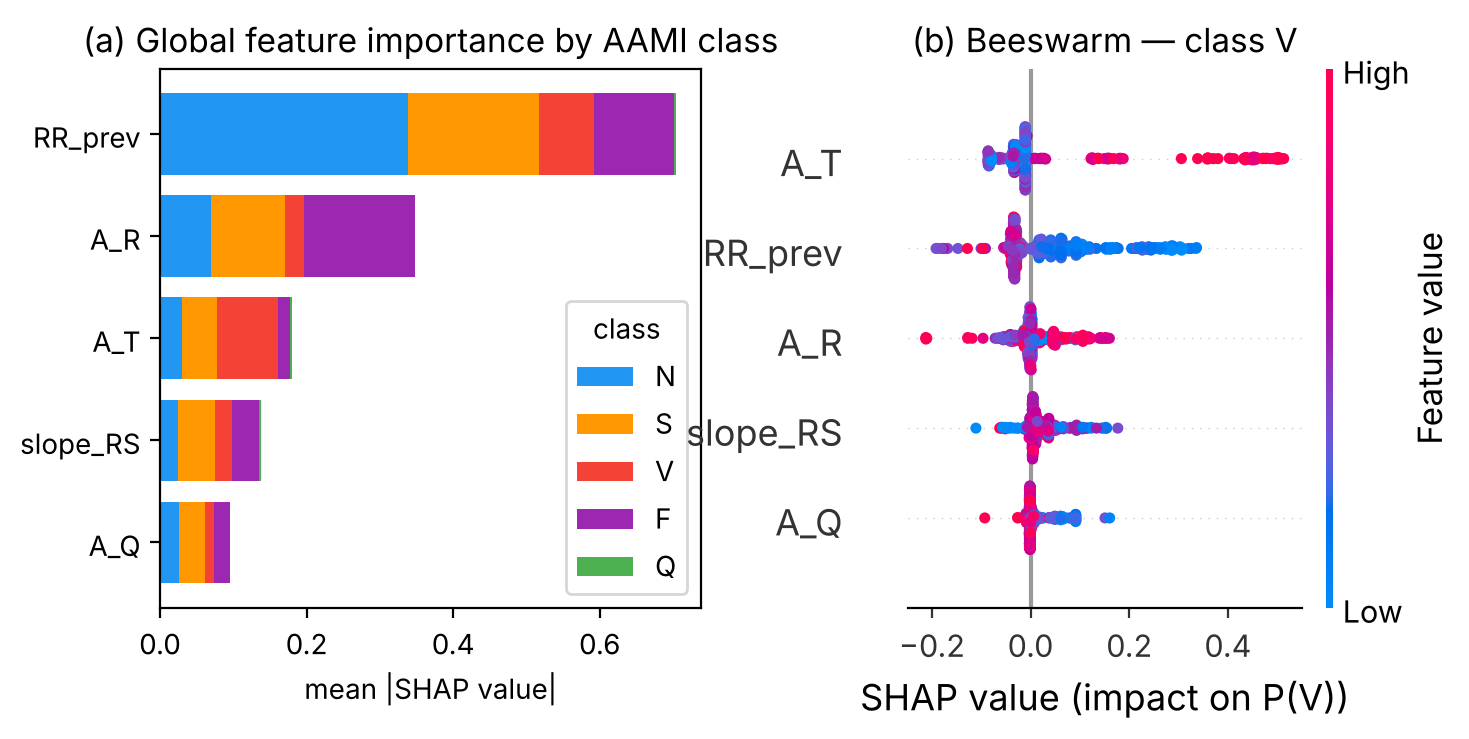

In [17]:
# ---- Fig. 4: (a) stacked mean |SHAP| per class, (b) beeswarm for class V ----
COL = {'N': '#2196F3', 'S': '#FF9800', 'V': '#F44336', 'F': '#9C27B0', 'Q': '#4CAF50'}
kV  = list(cls_cols).index(2)
fig = plt.figure(figsize=(14, 6)); gs = fig.add_gridspec(1, 2, width_ratios=[1.1, 1], wspace=0.4)
ax  = fig.add_subplot(gs[0]); top16 = shapT.index[:16]; left = np.zeros(len(top16))
for c in shapT.columns[:-1]:
    ax.barh(top16, shapT.loc[top16, c], left=left, color=COL[c], label=c); left += shapT.loc[top16, c].values
ax.invert_yaxis(); ax.set_xlabel("mean |SHAP value|"); ax.legend(title="class")
ax.set_title("(a) Global feature importance by AAMI class")
ax2 = fig.add_subplot(gs[1]); plt.sca(ax2)
shap.plots.beeswarm(shap.Explanation(values=sv[:, :, kV], base_values=np.full(len(Xs), base[kV]),
                                     data=Xs, feature_names=feat_best), max_display=14, show=False)
ax2.set_title("(b) Beeswarm — class V"); ax2.set_xlabel("SHAP value (impact on P(V))")
plt.savefig(f"{FIG_DIR}/fig4_shap_importance.png", dpi=200, bbox_inches='tight'); plt.show()

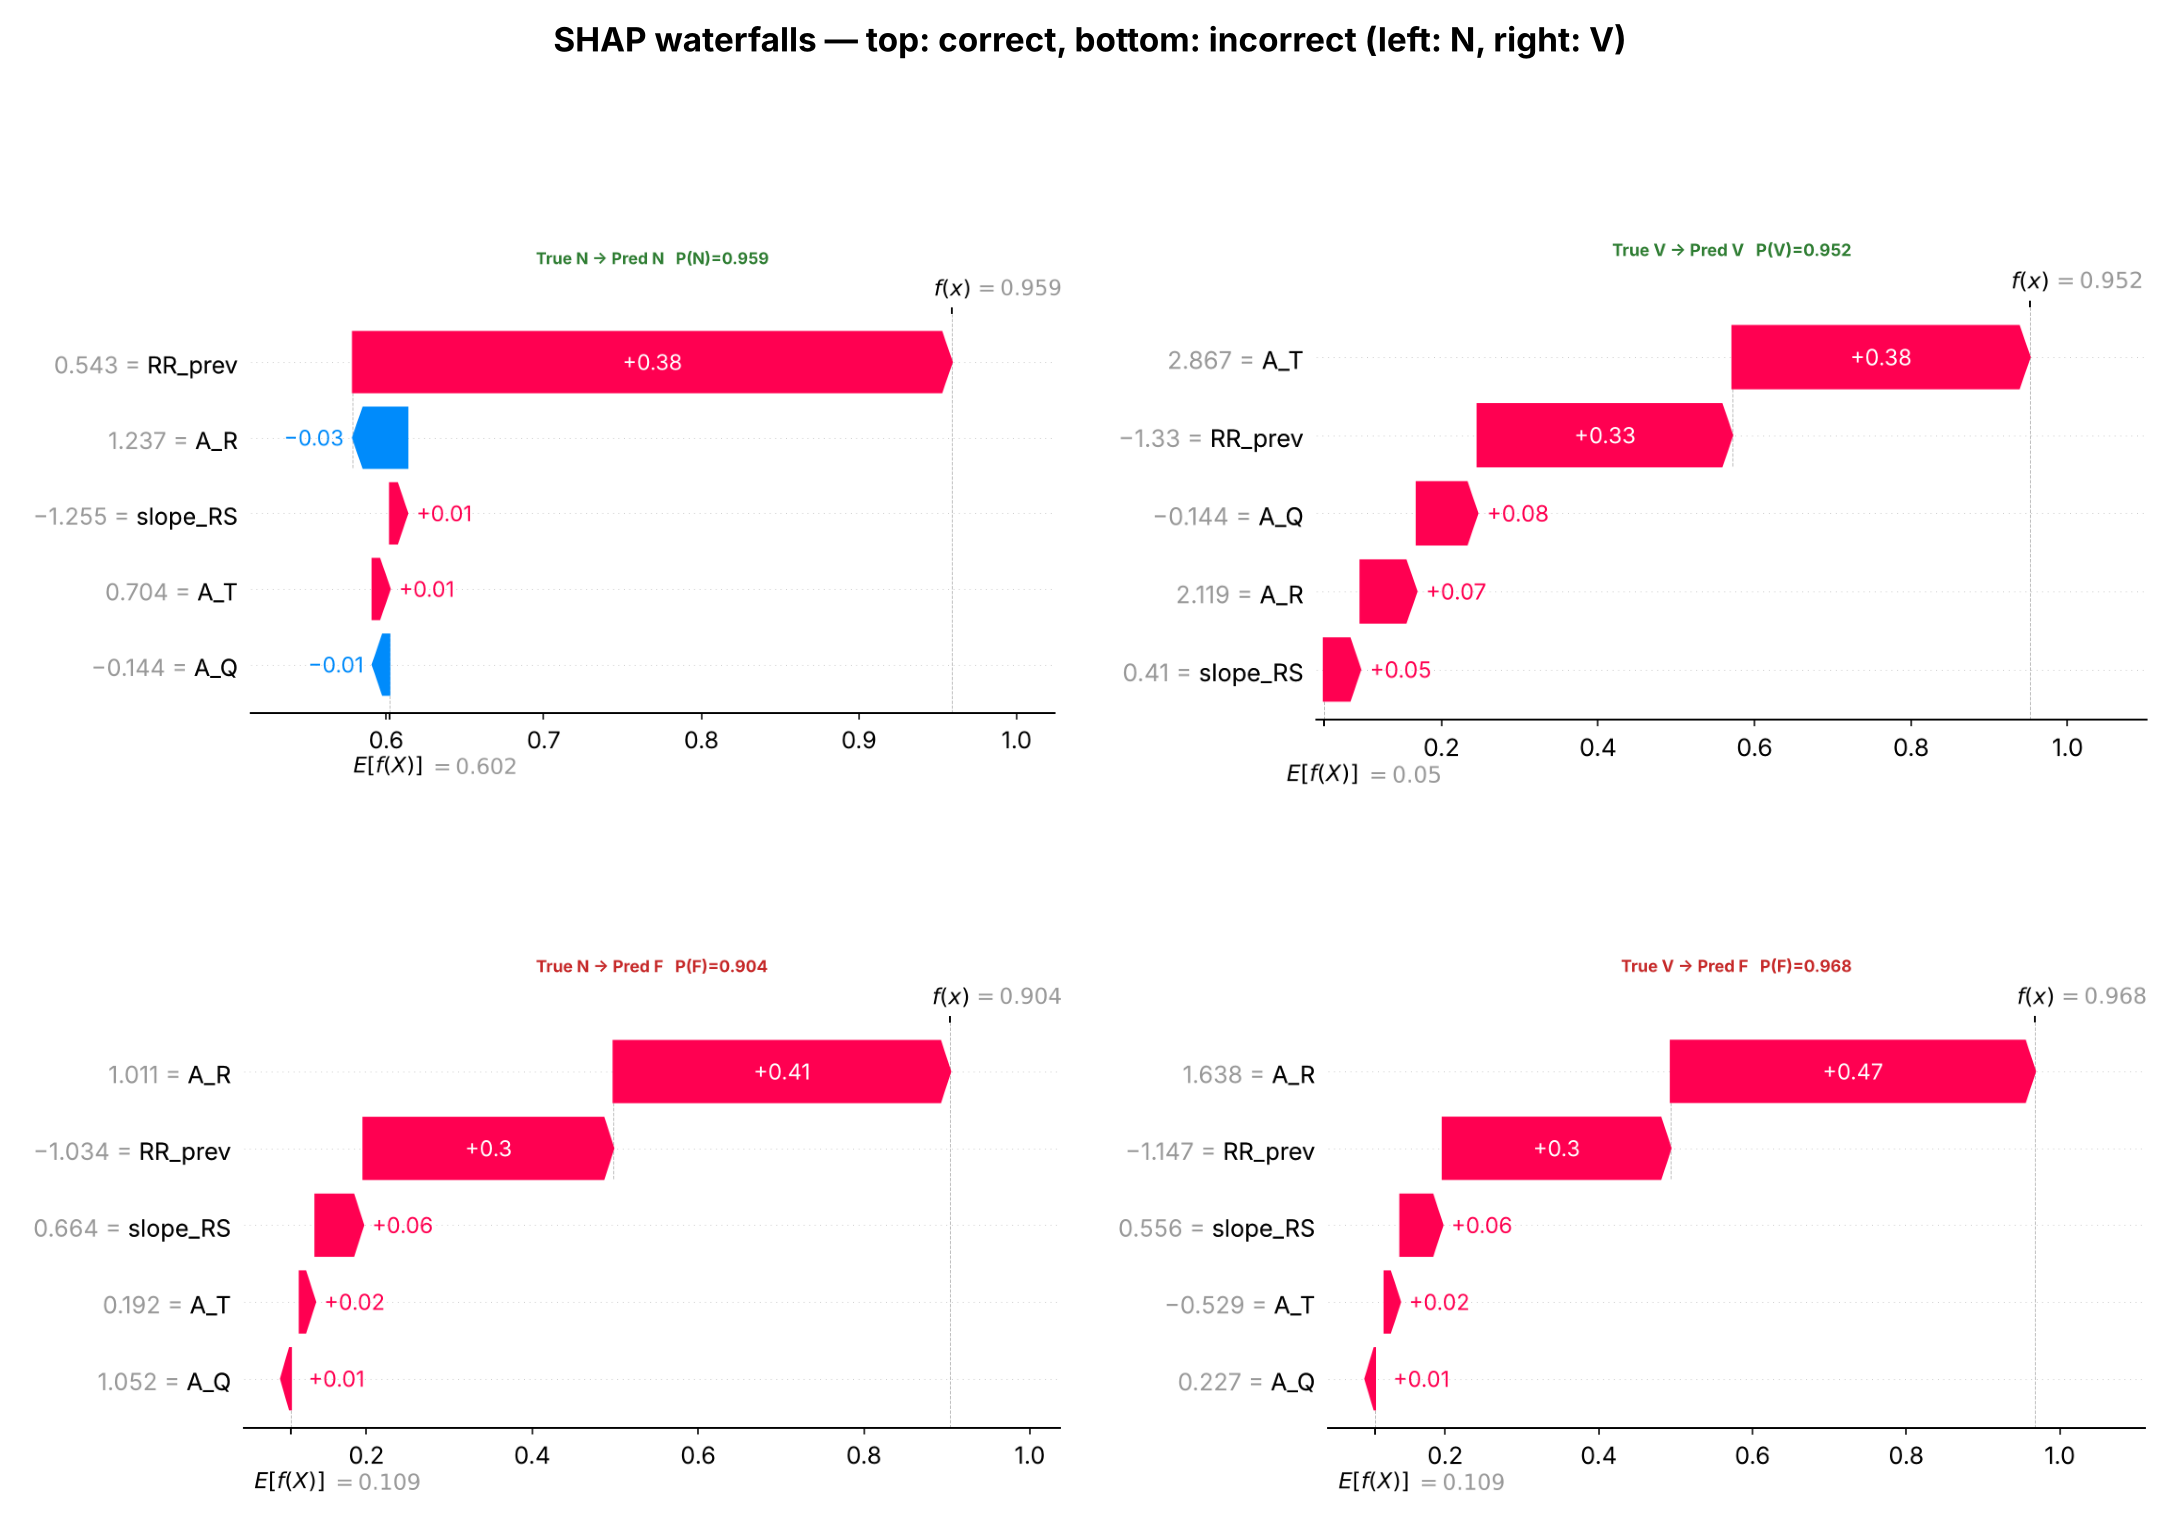

In [18]:
# ---- Fig. 5: waterfalls for N and V, most confident correct vs most confident wrong ----
def waterfall_img(i, k, title, colour):
    """Draw one waterfall in its own figure and return it as an image.
    (shap.plots.waterfall always draws on the current figure, so sub-plots cannot be used.)"""
    f = plt.figure(figsize=(4.4, 3.6))
    shap.plots.waterfall(shap.Explanation(values=sv[i, :, k], base_values=float(base[k]),
                                          data=Xs[i], feature_names=feat_best), max_display=8, show=False)
    a = plt.gca(); a.set_title(title, fontsize=9, color=colour, fontweight='bold')
    buf = io.BytesIO(); f.savefig(buf, dpi=140, bbox_inches='tight', facecolor='white'); plt.close(f)
    buf.seek(0); return plt.imread(buf)

def pick(c, correct):
    """Index of the most confident beat of true class c that was predicted right / wrong."""
    m = np.where((ys == c) & ((ps == c) if correct else (ps != c)))[0]
    return None if len(m) == 0 else int(m[np.argmax(Ps[m, ps[m]])])

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
for j, c in enumerate([0, 2]):
    for r, correct in enumerate([True, False]):
        a = axes[r, j]; a.axis('off'); i = pick(c, correct)
        if i is None or ps[i] not in cls_cols:
            a.text(.5, .5, f"no {'correct' if correct else 'wrong'} {CLASSES[c]} beat in the sample", ha='center'); continue
        k = list(cls_cols).index(ps[i])            # explain the PREDICTED class
        a.imshow(waterfall_img(i, k, f"True {CLASSES[c]} → Pred {CLASSES[ps[i]]}   P({CLASSES[ps[i]]})={Ps[i, ps[i]]:.3f}",
                               '#2E7D32' if correct else '#C62828'))
fig.suptitle("SHAP waterfalls — top: correct, bottom: incorrect (left: N, right: V)", fontweight='bold')
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig5_shap_waterfall_NV.png", dpi=200); plt.show()

## 11. Paper vs this run
Left: numbers printed in the manuscript (Table V, RF rows). Right: numbers produced above.
Use this table to update the manuscript.

In [19]:
PAPER5 = pd.DataFrame({                       # transcribed from Table V of the manuscript
    'RF_ALL (non-causal)': [96.9, 63.8, 0.776, 0.862, 57.9, 55.6],
    'RF_CAUSAL'          : [96.4, 74.3, 0.771, 0.857, 48.3, 46.2],
    'RF_TOP10'           : [95.8, 63.1, 0.754, 0.841, 49.1, 47.8],
    'ECG-CaRE-ES'        : [96.2, 74.0, 0.768, 0.854, 58.5, 36.5],
    'ECG-CaRE+MOBO'      : [95.9, 74.1, 0.869, 0.856, 37.6, 35.1],
}, index=['Acc', 'BalAcc', 'MCC', 'MaF1', 'FNR_V', 'FNR_S']).T
cmp = PAPER5.add_suffix(' (paper)').join(tab5[PAPER5.columns].add_suffix(' (this run)'))
cmp = cmp[[f"{m} ({s})" for m in PAPER5.columns for s in ('paper', 'this run')]]
cmp.to_csv(f"{OUT_DIR}/paper_vs_reproduced_table5.csv")
print("Files written:"); [print("  ", OUT_DIR + "/" + f) for f in sorted(os.listdir(OUT_DIR))]
[print("  ", FIG_DIR + "/" + f) for f in sorted(os.listdir(FIG_DIR))]
cmp.round(3)

Files written:
   results/best_params.json
   results/gini_ranking.csv
   results/mobo_all_trials.csv
   results/paper_vs_reproduced_table5.csv
   results/pareto_dart.csv
   results/shap_mean_abs_per_class.csv
   results/table1_class_counts.csv
   results/table4_shap_top5_per_class.csv
   results/table5_diagnostic_ds2.csv
   results/table6_dart_top5.csv
   results/table7_early_stopping.csv
   results/table8_deployability.csv
   figures/fig2_mobo.png
   figures/fig3_feature_importance.png
   figures/fig4_shap_importance.png
   figures/fig5_shap_waterfall_NV.png


,Acc (paper),Acc (this run),BalAcc (paper),BalAcc (this run),MCC (paper),MCC (this run),MaF1 (paper),MaF1 (this run),FNR_V (paper),FNR_V (this run),FNR_S (paper),FNR_S (this run)
RF_ALL (non-causal),96.9,84.954,63.8,41.881,0.776,0.447,0.862,0.366,57.9,12.271,55.6,90.468
RF_CAUSAL,96.4,84.195,74.3,37.579,0.771,0.419,0.857,0.339,48.3,12.954,46.2,95.370
RF_TOP10,95.8,81.068,63.1,36.326,0.754,0.375,0.841,0.334,49.1,14.135,47.8,93.900
ECG-CaRE-ES,96.2,84.106,74.0,37.391,0.768,0.415,0.854,0.338,58.5,13.917,36.5,95.316
ECG-CaRE+MOBO,95.9,70.071,74.1,42.374,0.869,0.257,0.856,0.345,37.6,47.592,35.1,77.070
